# 10 · Confounding and noise diagnostics

An SCM rests on assumptions about its noise: one law shared by several parent
configurations, one law tied across nodes, fresh noise at every step, and no
hidden confounding in the data.  `nbn.scm` has a test for each.  Here three
behaviour policies log the same rehab environment.  A hidden strength `W`
changes the effect of exercising.  The "doctor" sees `W` when it decides, so its
data are confounded; the other two loggers are not.

- **NBN API:** `nbn.scm.transitions_from_episodes`, `context_invariance_test`,
  `noise_sharing_test`, `noise_tying_test`, `freshness_test`, `residuals`,
  `benjamini_hochberg`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

The four diagnostics:

* `context_invariance_test`: does `P(health' | health, exercise)` change with
  the logger?  (policy-as-context test; a rejection flags confounding)
* `noise_sharing_test` / `noise_tying_test`: may parent configurations /
  several nodes share one noise law?
* `freshness_test`: is the noise drawn afresh at every step?

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn.scm import (
    DiscreteAdditiveNoiseMechanism,
    StructuralCausalModel,
    benjamini_hochberg,
    context_invariance_test,
    freshness_test,
    noise_sharing_test,
    noise_tying_test,
    residuals,
    transitions_from_episodes,
)
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The data

300 episodes of 10 steps per logger.  `transitions_from_episodes` flattens the
trajectories into one row per step, with `episode` and `time` columns.
`W` is drawn afresh at every step and never logged.

In [2]:
torch.manual_seed(0)
NOISE = torch.tensor([0.15, 0.70, 0.15])


def episodes(policy: str, n_episodes: int = 300, horizon: int = 10) -> dict:
    """Trajectories of (health, fatigue) under one logger; W is hidden and fresh each step."""
    health = torch.zeros(n_episodes, horizon + 1, dtype=torch.long)
    fatigue = torch.zeros(n_episodes, horizon + 1, dtype=torch.long)
    action = torch.zeros(n_episodes, horizon, dtype=torch.long)
    health[:, 0] = torch.randint(0, 4, (n_episodes,))
    for t in range(horizon):
        strong = torch.rand(n_episodes) < 0.4                      # hidden W
        if policy == "random":
            a = torch.rand(n_episodes) < 0.5
        elif policy == "state_based":
            a = health[:, t] < 2
        else:                                                      # "doctor" sees W
            a = torch.rand(n_episodes) < torch.where(strong, 0.9, 0.1)
        a = a.long()
        effect = a * (2 * strong.long() - 1)                       # helps strong, hurts weak
        u = torch.multinomial(NOISE, n_episodes, replacement=True) - 1
        v = torch.multinomial(NOISE, n_episodes, replacement=True) - 1
        health[:, t + 1] = (health[:, t] + effect + u).clamp(0, 3)
        fatigue[:, t + 1] = (a + v).clamp(0, 1)
        action[:, t] = a
    return transitions_from_episodes({"health": health.float(), "fatigue": fatigue.float()},
                                     {"exercise": action.float()})


loggers = ["random", "state_based", "doctor"]
parts = [episodes(p) for p in loggers]
data = {k: torch.cat([p[k] for p in parts]) for k in parts[0]}
data["logger"] = torch.cat([torch.full_like(p["time"], i) for i, p in enumerate(parts)]).float()
data["episode"] = torch.cat([p["episode"] + 1000 * i for i, p in enumerate(parts)])

What the loggers see: the next health after exercising at health 1.  The
doctor exercises mostly when `W` is strong, so in its data exercising looks
much better than it is.

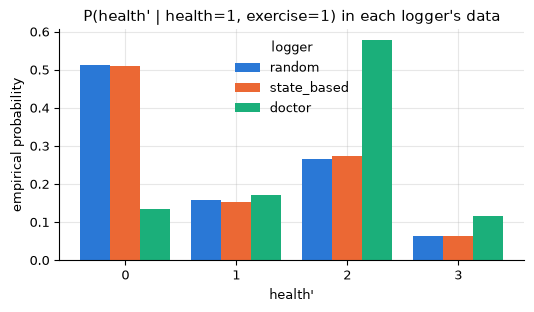

In [3]:
def next_health_law(rows: dict, health: int, exercise: int) -> torch.Tensor:
    """Empirical P(health' | health, exercise) from the rows."""
    keep = (rows["health"].reshape(-1) == health) & (rows["exercise"].reshape(-1) == exercise)
    nxt = rows["health'"].reshape(-1)[keep].long()
    return torch.bincount(nxt, minlength=4).float() / max(int(keep.sum()), 1)


fig, ax = plt.subplots(figsize=(6, 3))
width = 0.27
for i, (name, color) in enumerate(zip(loggers, (BLUE, ORANGE, AQUA))):
    law = next_health_law({k: v[data["logger"].reshape(-1) == i] for k, v in data.items()}, 1, 1)
    ax.bar([k + (i - 1) * width for k in range(4)], to_numpy(law), width, color=color, label=name)
ax.set(xticks=range(4), xlabel="health'", ylabel="empirical probability",
       title="P(health' | health=1, exercise=1) in each logger's data")
ax.legend(frameon=False, title="logger", loc="upper center")
plt.show()

## 1. Policy-as-context test

The logger is a context variable.  Without confounding, `P(health' | health,
exercise)` is the same in every logger's data.  We run the test on the two
clean loggers, then on all three.

`health'` moves by the exercise effect (±1, depending on the hidden `W`) plus
`U` (±1): seen without `W`, offsets reach ±2.  With `max_offset=1` the fit
refuses the data with a clear error instead of silently misfitting.

The p-value is a **permutation** p-value (the default): within each parent
configuration the logger labels are shuffled, 999 times, and
`p = (1 + #{shuffled G >= observed G}) / 1000`.  So the smallest possible
value is 0.001.  `reference="chi2"` gives the classic chi-square approximation
instead; section 1b shows when the two differ.

In [4]:
def model_for(rows: dict) -> StructuralCausalModel:
    model = StructuralCausalModel(
        [("health", "health'"), ("exercise", "health'"), ("exercise", "fatigue'")],
        {"health": ("discrete", 4), "exercise": ("discrete", 2), "health'": ("discrete", 4),
         "fatigue'": ("discrete", 2), "logger": ("discrete", 3)},
        context="logger", device=device,
    )
    model.set_mechanism("health'", DiscreteAdditiveNoiseMechanism(max_offset=2))
    model.set_mechanism("fatigue'", DiscreteAdditiveNoiseMechanism(max_offset=1))
    model.auto_mechanisms()
    model.fit({k: rows[k] for k in ("health", "exercise", "health'", "fatigue'", "logger")})
    return model


p_values = {}
print("context invariance of health' (H0: the logger does not matter given the parents)")
for name, keep in [("random + state_based", data["logger"] < 2), ("all three loggers", None)]:
    rows = data if keep is None else {k: v[keep] for k, v in data.items()}
    model = model_for(rows)
    result = context_invariance_test(model, rows, "health'", generator=torch.Generator().manual_seed(0))
    chi2_p = context_invariance_test(model, rows, "health'", reference="chi2").p_value
    p_values[f"context: {name}"] = result.p_value
    print(f"  {name:22s} p = {result.p_value:.3f}  (chi-square: {chi2_p:.2g})  ->  "
          f"{'confounding or drift detected' if result.rejected() else 'no evidence of confounding'}")

context invariance of health' (H0: the logger does not matter given the parents)
  random + state_based   p = 0.700  (chi-square: 0.69)  ->  no evidence of confounding
  all three loggers      p = 0.001  (chi-square: 1.4e-90)  ->  confounding or drift detected


## 1b. Why a permutation reference: many sparse strata

The test sums one G statistic per parent configuration.  With many
configurations and few rows in each, the chi-square approximation of that sum
is too optimistic: it rejects a **true** null more often than its level.
Here a node has six binary parents (64 configurations) and two unconfounded
loggers share 200 rows, about 3 per configuration and logger.  We draw 1000
such datasets under the null and count how often each reference rejects at
5%.  Under a true null a valid p-value is uniform (or larger), so its
empirical CDF should lie on or under the diagonal.

In [5]:
N_PA = 6
sparse = StructuralCausalModel(
    [(f"x{i}", "y") for i in range(N_PA)],
    {**{f"x{i}": ("discrete", 2) for i in range(N_PA)}, "y": ("discrete", 2), "c": ("discrete", 2)},
    context="c", device=device,
)  # the discrete test reads only the graph and the cardinalities: no fit needed


def null_rows(n: int, gen: torch.Generator) -> dict:
    """y depends on the parity of its parents, the same way under both loggers c."""
    x = torch.randint(0, 2, (n, N_PA), generator=gen)
    y = torch.rand(n, generator=gen) < 0.2 + 0.6 * (x.sum(1) % 2).float()
    rows = {f"x{i}": x[:, i].float() for i in range(N_PA)}
    return rows | {"y": y.float(), "c": torch.randint(0, 2, (n,), generator=gen).float()}


gen = torch.Generator().manual_seed(1)
p_perm, p_chi2 = [], []
for _ in range(1000):
    rows = null_rows(200, gen)
    p_perm.append(context_invariance_test(sparse, rows, "y", n_perm=199, generator=gen).p_value)
    p_chi2.append(context_invariance_test(sparse, rows, "y", reference="chi2").p_value)
p_perm, p_chi2 = torch.tensor(p_perm), torch.tensor(p_chi2)
print("rejection rate of a true null at level 0.05 (1000 datasets)")
print(f"  permutation  {float((p_perm <= 0.05).float().mean()):.3f}")
print(f"  chi-square   {float((p_chi2 <= 0.05).float().mean()):.3f}")

rejection rate of a true null at level 0.05 (1000 datasets)
  permutation  0.047
  chi-square   0.800


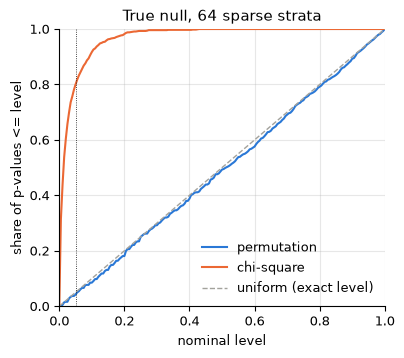

In [6]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
grid = torch.linspace(0, 1, 201)
for p, color, label in ((p_perm, BLUE, "permutation"), (p_chi2, ORANGE, "chi-square")):
    ax.plot(to_numpy(grid), to_numpy((p.unsqueeze(1) <= grid).float().mean(0)), color=color, label=label)
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="uniform (exact level)")
ax.axvline(0.05, color=INK, lw=0.6, ls=":")
ax.set(xlabel="nominal level", ylabel="share of p-values <= level", xlim=(0, 1), ylim=(0, 1),
       title="True null, 64 sparse strata")
ax.legend(frameon=False, loc="lower right")
plt.show()

The chi-square curve lies far above the diagonal at small levels: it rejects
a true null too often.  The permutation curve follows the diagonal, within the
sampling noise of 1000 datasets.
`reference="chi2"` remains available for large tables where every
configuration has many rows: it is faster, and there the two references
agree.

## 2. Noise diagnostics on the clean loggers

Confounded rows never feed do-estimates, so we drop the doctor's data and test
the noise assumptions on the rest.  Three tests at once: Benjamini–Hochberg
controls the false discovery rate at 5%.

In [7]:
clean = {k: v[data["logger"] < 2] for k, v in data.items()}
model = model_for(clean)
results = {
    "sharing (health')": noise_sharing_test(model, clean, "health'"),
    "tying (health', fatigue')": noise_tying_test(model, clean, ["health'", "fatigue'"]),
    "freshness (health')": freshness_test(residuals(model, clean, "health'"),
                                          clean["episode"], clean["time"]),
}
reject = benjamini_hochberg(torch.tensor([r.p_value for r in results.values()]), alpha=0.05)
print("noise diagnostics on the clean loggers (Benjamini-Hochberg at 5%)")
for (name, r), rej in zip(results.items(), reject.tolist()):
    print(f"  {name:28s} p = {r.p_value:.3f}  {'REJECT' if rej else 'ok'}   H0: {r.null}")
p_values.update({name: r.p_value for name, r in results.items()})

noise diagnostics on the clean loggers (Benjamini-Hochberg at 5%)
  sharing (health')            p = 0.005  REJECT   H0: one offset law for every parent configuration of 'health''
  tying (health', fatigue')    p = 0.005  REJECT   H0: one offset law shared by ["health'", "fatigue'"]
  freshness (health')          p = 0.102  ok   H0: residuals at t and t+1 are uncorrelated


Why sharing is rejected: on the clean data, the next health after health 1
is narrow without exercise (noise only) and wide with exercise (noise plus the
hidden ±1 effect).  No single offset law gives both shapes.

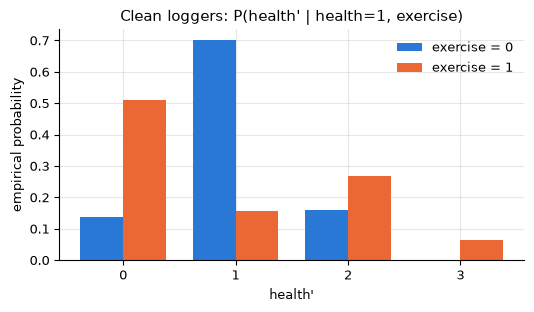

In [8]:
fig, ax = plt.subplots(figsize=(6, 3))
for i, (exercise, color) in enumerate(((0, BLUE), (1, ORANGE))):
    law = next_health_law(clean, health=1, exercise=exercise)
    ax.bar([k + (i - 0.5) * 0.38 for k in range(4)], to_numpy(law), 0.38, color=color,
           label=f"exercise = {exercise}")
ax.set(xticks=range(4), xlabel="health'", ylabel="empirical probability",
       title="Clean loggers: P(health' | health=1, exercise)")
ax.legend(frameon=False)
plt.show()

All five p-values, as `-log10(p)`: longer bars are stronger evidence against
the null hypothesis.  The dashed line is p = 0.05.  The three noise tests are
judged together by Benjamini–Hochberg, which here rejects the same two.  The
confounded-logger bar stops at 3, the permutation floor p = 0.001: none of
the 999 shuffles reached the observed statistic.

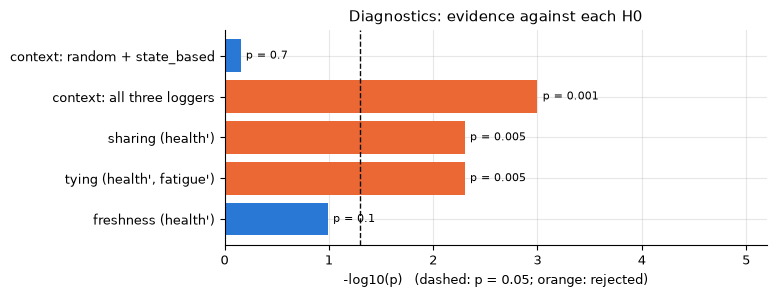

In [9]:
import math

names = list(p_values)
cap = 4.0
fig, ax = plt.subplots(figsize=(7, 2.8))
for y, name in enumerate(names):
    p = p_values[name]
    score = -math.log10(max(p, 1e-300))
    ax.barh(y, min(score, cap), color=ORANGE if p < 0.05 else BLUE)
    note = f"p = {p:.2g}" + ("  (off scale)" if score > cap else "")
    ax.text(min(score, cap) + 0.05, y, note, va="center", fontsize=8)
ax.axvline(-math.log10(0.05), color=INK, ls="--", lw=1)
ax.set(yticks=range(len(names)), yticklabels=names, xlim=(0, cap + 1.2),
       xlabel="-log10(p)   (dashed: p = 0.05; orange: rejected)", title="Diagnostics: evidence against each H0")
ax.invert_yaxis()
plt.show()

## Reading the results

* Only the doctor's data change `P(health' | health, exercise)`: it saw `W`.
* The policy-as-context p-value is a permutation p-value: its level holds at
  any sample size, including many sparse parent configurations, where the
  chi-square approximation over-rejects (section 1b).  Its smallest value is
  `1 / (n_perm + 1)`; raise `n_perm` if a decision needs a smaller one.
* Sharing is rejected even on clean data: with `W` hidden, exercising adds a
  ±1 mixture, so the noise of `health'` really depends on `exercise`.  One
  shared law would be a wrong (too tight) model.  Use a full table for
  `health'` (`CategoricalTableMechanism`), or observe `W`.
* Tying `health'` and `fatigue'` is rejected for the same reason.
* Freshness: no evidence against fresh noise (`W` is drawn anew each step in
  this simulator).  A pass is not a proof; it is the check that per-step
  confounding bounds (Manski / causal Bellman rows) need.
* For discrete nodes, `residuals` are random draws from the posterior of the
  noise, so the freshness p-value changes with the random stream (for example
  on another device).  Read it as one draw, not as a fixed number.